# Telco Customer Churn Prediction


## 1. Import libraries


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

## 2. Load and inspect the data

In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [3]:
print(df.columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


In [4]:
print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


## 3. Clean the data

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna()
df = df.drop("customerID", axis=1)
df["Churn"] = df["Churn"].replace({"Yes": 1, "No": 0}).astype(int)

print("Rows remaining:", len(df))
df.head()

Rows remaining: 7032


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 4. Convert words into numbers

In [6]:
telecom_cust_dummies = pd.get_dummies(df, drop_first=True, dtype=int)
telecom_cust_dummies.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


## 5. Explore the data with graphs

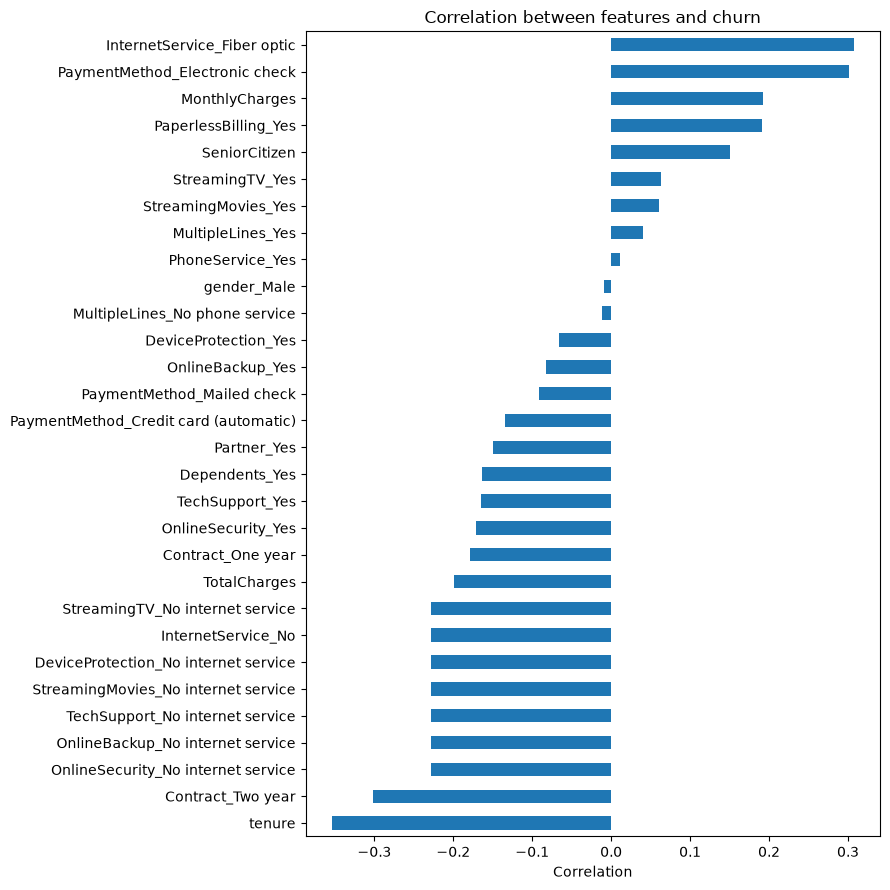

In [7]:
churn_corr = telecom_cust_dummies.corr()["Churn"].drop("Churn").sort_values()
plt.figure(figsize=(9, 9))
churn_corr.plot(kind="barh")
plt.title("Correlation between features and churn")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

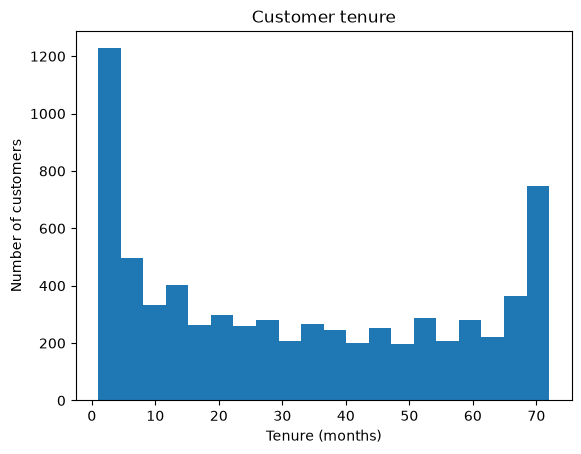

In [8]:
plt.hist(df["tenure"], bins=20)
plt.title("Customer tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of customers")
plt.show()

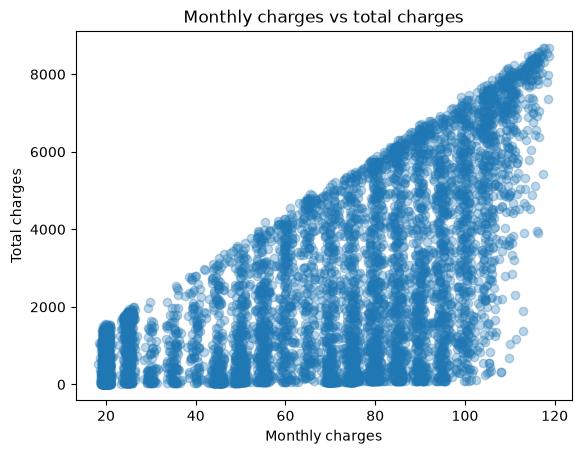

In [9]:
plt.scatter(df["MonthlyCharges"], df["TotalCharges"], alpha=0.3)
plt.title("Monthly charges vs total charges")
plt.xlabel("Monthly charges")
plt.ylabel("Total charges")
plt.show()

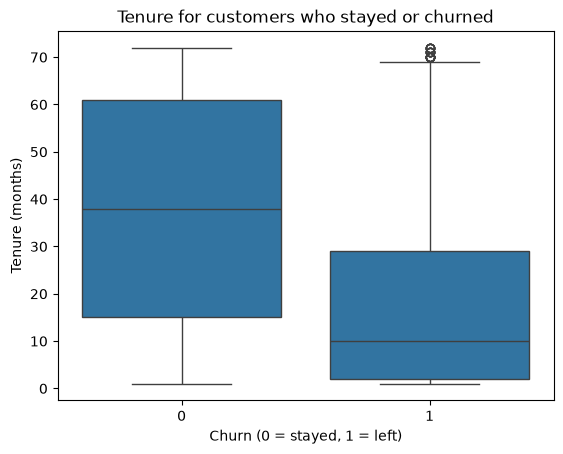

In [10]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure for customers who stayed or churned")
plt.xlabel("Churn (0 = stayed, 1 = left)")
plt.ylabel("Tenure (months)")
plt.show()

## 6. Prepare the data

In [11]:
X = telecom_cust_dummies.drop("Churn", axis=1)
y = telecom_cust_dummies["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training customers:", len(y_train))
print("Testing customers:", len(y_test))

Training customers: 5274
Testing customers: 1758


## 7. Logistic regression

In [12]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

log_predictions = log_model.predict(X_test)
log_accuracy = accuracy_score(y_test, log_predictions)
print("Logistic regression accuracy:", round(log_accuracy * 100, 2), "%")

Logistic regression accuracy: 80.6 %


## 8. Random forest

In [13]:
forest_model = RandomForestClassifier(
    n_estimators=2000,
    oob_score=True,
    max_features="sqrt",
    max_leaf_nodes=50,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

forest_accuracy = accuracy_score(y_test, forest_predictions)
oob_error = 1 - forest_model.oob_score_

print("Random forest accuracy:", round(forest_accuracy * 100, 2), "%")
print("Random forest OOB error:", round(oob_error * 100, 2), "%")

Random forest accuracy: 79.18 %
Random forest OOB error: 20.08 %


## 9. Evaluate both models

In [14]:
print("Logistic regression confusion matrix:")
print(confusion_matrix(y_test, log_predictions))
print("\nRandom forest confusion matrix:")
print(confusion_matrix(y_test, forest_predictions))

Logistic regression confusion matrix:
[[1150  141]
 [ 200  267]]

Random forest confusion matrix:
[[1174  117]
 [ 249  218]]


In [15]:
log_precision = precision_score(y_test, log_predictions)
log_recall = recall_score(y_test, log_predictions)
forest_precision = precision_score(y_test, forest_predictions)
forest_recall = recall_score(y_test, forest_predictions)

print("Logistic regression precision:", round(log_precision, 3))
print("Logistic regression recall:", round(log_recall, 3))
print("Random forest precision:", round(forest_precision, 3))
print("Random forest recall:", round(forest_recall, 3))

Logistic regression precision: 0.654
Logistic regression recall: 0.572
Random forest precision: 0.651
Random forest recall: 0.467


## 10. Compare the models

In [16]:
results = pd.DataFrame({
    "Model": ["Logistic regression", "Random forest"],
    "Accuracy": [log_accuracy, forest_accuracy],
    "Precision": [log_precision, forest_precision],
    "Recall": [log_recall, forest_recall]
})
print(results.round(3))

                 Model  Accuracy  Precision  Recall
0  Logistic regression     0.806      0.654   0.572
1        Random forest     0.792      0.651   0.467


### Simple discussion

The confusion matrices show the number of correct and incorrect predictions. The bottom-left number is the number of customers who churned but were missed by the model. This is important because the company might lose these customers without trying to keep them.

Precision tells us how often a predicted churner really churns. Recall tells us how many actual churners the model manages to find. High recall is useful when the company wants to contact customers who may leave.

### Conclusion

I would choose logistic regression for this task.It had an accuracy of 80.60%, compared with 79.18% for random forest. Logistic regression also had higher recall (57.17% versus 46.68%), meaning that it correctly identified more of the customers who actually churned. Its precision was slightly better too (65.44% versus 65.07%).

The random forest's OOB error was 20.08%, suggesting that it makes incorrect predictions roughly one time in five using its out-of-bag estimates. Both models could still improve because they miss some customers who churn.